### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [16]:
data = pd.read_csv('data/coupons.csv')

In [17]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [18]:
#Missing Data
# data.info() 12684 entries, 0 to 12683
missing_data = data.isnull().sum().sort_values(ascending=False)
missing_data_detail = pd.DataFrame({"missing_count": data.isnull().sum(), "missing_percent":data.isnull().mean()*100})


#duplicate data
dup_count = data.duplicated().sum()

missing_data
missing_data_detail


,missing_count,missing_percent
destination,0,0.000000
passanger,0,0.000000
weather,0,0.000000
temperature,0,0.000000
time,0,0.000000
coupon,0,0.000000
expiration,0,0.000000
gender,0,0.000000
age,0,0.000000
maritalStatus,0,0.000000


3. Decide what to do about your missing data -- drop, replace, other...

In [19]:
#Remove car column since 99.1 percent data is missing
coupons = data.drop(columns="car")

#Replace the blank values in column Bar, CoffeeHouse, CarryAway, RestaurantLessThan20 and Restaurant20To50 to Unknown
Repl_columns = ["Bar","CoffeeHouse","CarryAway","RestaurantLessThan20","Restaurant20To50"]
coupons[Repl_columns] = (coupons[Repl_columns].fillna("Unknown"))
#coupons.info()
#data.info()



4. What proportion of the total observations chose to accept the coupon?



In [20]:
#Proportion on accepts (Y=1)
acceptance_rate = coupons["Y"].mean()
print(f"Overall acceptance rate: {acceptance_rate:.1%}")

coupon_summary = (
    coupons.groupby("coupon")["Y"]
    .agg(observations="count", acceptance_rate="mean")
    .sort_values("acceptance_rate", ascending=False)
)

coupon_summary["acceptance_rate"] *= 100
coupon_summary

Overall acceptance rate: 56.8%


,observations,acceptance_rate
coupon,,
Carry out & Take away,2393,73.547848
Restaurant(<20),2786,70.710696
Coffee House,3996,49.924925
Restaurant(20-50),1492,44.101877
Bar,2017,41.001487


5. Use a bar plot to visualize the `coupon` column.

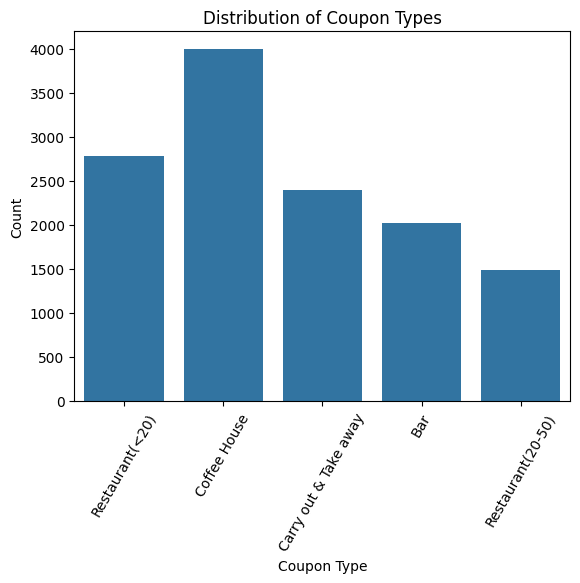

In [21]:
sns.countplot(data=coupons, x='coupon')
plt.xticks(rotation=60)
plt.xlabel('Coupon Type')
plt.ylabel('Count')
plt.title('Distribution of Coupon Types')
plt.show()

6. Use a histogram to visualize the temperature column.

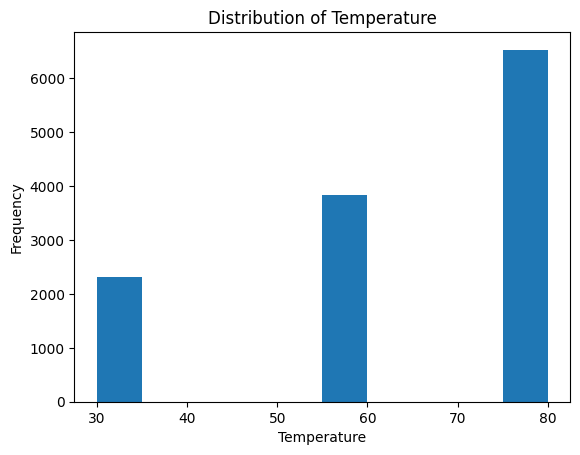

In [22]:
plt.hist(coupons['temperature'])
plt.xlabel('Temperature')
plt.ylabel('Frequency')
plt.title('Distribution of Temperature')
plt.show()

The dataset contained **12,684 observations** covering customer demographics, driving context, coupon characteristics, prior venue behavior, and whether the coupon was accepted.

Initial exploratory analysis identified the following data-quality considerations:

1. **Missing data:** The car column was approximately 99% missing and provided little analytical value. Smaller amounts of missing data were found in Bar, CoffeeHouse, CarryAway, RestaurantLessThan20, and Restaurant20To50.

**Clean up ** This was addressed by deleting the car column. The blank values in the other columns where updated to Unknown,

2. The overall acceptance rate was 56.8% for the coupons.

3. **Temperature impact**

    The dataset has only three temperature values:

    30°F: 2,316 observations
    55°F: 3,840 observations
    80°F: 6,528 observations

    So, most driving scenarios in the dataset occurred at 80°F.

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [23]:
#Bar Coupons
bar_coupons = coupons[coupons['coupon'] == 'Bar']
bar_coupons.head(20)
bar_coupons.shape

(2017, 25)

2. What proportion of bar coupons were accepted?


In [24]:
# Proportion of Bar Coupons accepted
bar_accept = bar_coupons['Y'].mean()
print(f"Bar coupon acceptance rate: {bar_accept:.1%}")
bar_accept

Bar coupon acceptance rate: 41.0%


np.float64(0.41001487357461575)

3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


 Acceptance rate for 3 or fewer Bar visits: 37.062%
 Acceptance rate formore than 3 Bar visits: 76.884%


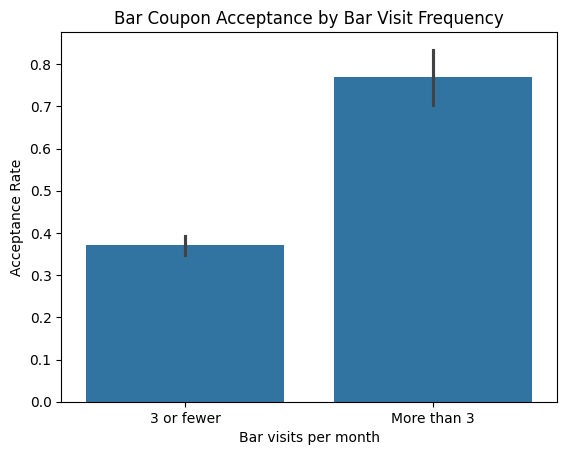

In [25]:
bar_3orless = bar_coupons[bar_coupons['Bar'].isin(['never','less1','1~3'])]
bar_morethan3 = bar_coupons[bar_coupons['Bar'].isin(['4~8','gt8'])]
print(f" Acceptance rate for 3 or fewer Bar visits: {bar_3orless['Y'].mean():.3%}")
print(f" Acceptance rate formore than 3 Bar visits: {bar_morethan3['Y'].mean():.3%}")

#Bar Plot
bar_couponsplt = bar_coupons.copy()

bar_couponsplt['bar_frequency'] = bar_couponsplt['Bar'].apply(
    lambda x: '3 or fewer'
    if x in ['never', 'less1', '1~3']
    else 'More than 3'
    if x in ['4~8', 'gt8']
    else None
)

sns.barplot(
    data=bar_couponsplt,
    x='bar_frequency',
    y='Y'
)

plt.xlabel('Bar visits per month')
plt.ylabel('Acceptance Rate')
plt.title('Bar Coupon Acceptance by Bar Visit Frequency')
plt.show()

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


More than once/month and over 25: 69.524%
All others: 33.500%
Yes those who go to a bar more than once a month and above the age of 25 accepted bar coupons roughly twice the rate of others


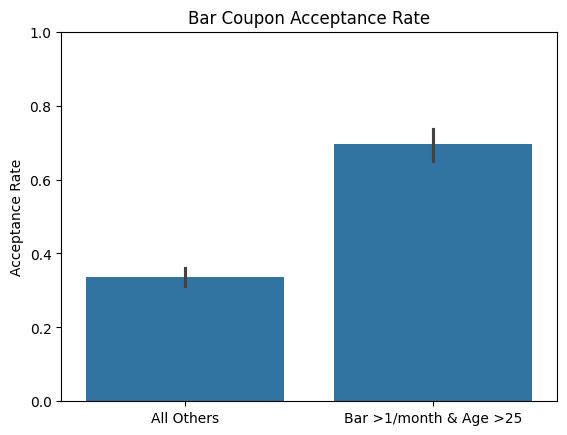

In [26]:
#Analysis on acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.
bar_more1_over25 = bar_coupons[
    (bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])) &
    (bar_coupons['age'].isin(['26', '31', '36', '41', '46', '50plus']))
]

all_others = bar_coupons[
    ~(
        (bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])) &
        (bar_coupons['age'].isin(['26', '31', '36', '41', '46', '50plus']))
    )
]

print(f"More than once/month and over 25: {bar_more1_over25['Y'].mean():.3%}")
print(f"All others: {all_others['Y'].mean():.3%}")
print(f"Yes those who go to a bar more than once a month and above the age of 25 accepted bar coupons roughly twice the rate of others")

##grpahical Analysis##
#Create the group columns
bar_couponsplt2 = bar_coupons.copy()

condition = (
    bar_couponsplt2['Bar'].isin(['1~3', '4~8', 'gt8']) &
    bar_couponsplt2['age'].isin(['26', '31', '36', '41', '46', '50plus'])
)

bar_couponsplt2['group'] = condition.map({
    True: 'Bar >1/month & Age >25',
    False: 'All Others'
})

#Plot
sns.barplot(
    data=bar_couponsplt2,
    x='group',
    y='Y'
)

plt.title('Bar Coupon Acceptance Rate')
plt.xlabel('')
plt.ylabel('Acceptance Rate')
plt.ylim(0, 1)

plt.show()

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


Drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry acceptance rate: 71.3%
All others acceptance rate: 29.6%
Drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry had a 41.7 percent higher acceptance rate than the others


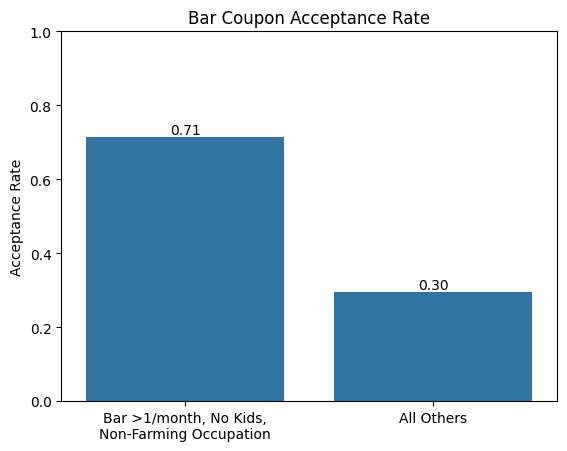

In [27]:
# Create the 2 groups for Analysis
target_group = bar_coupons[
    (bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])) &
    (bar_coupons['passanger'] != 'Kid(s)') &
    (bar_coupons['occupation'] != 'Farming Fishing & Forestry')
]

all_others = bar_coupons[
    ~(
        (bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])) &
        (bar_coupons['passanger'] != 'Kid(s)') &
        (bar_coupons['occupation'] != 'Farming Fishing & Forestry')
    )
]

print(f"Drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry acceptance rate: {target_group['Y'].mean():.1%}")
print(f"All others acceptance rate: {all_others['Y'].mean():.1%}")
print(f"Drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry had a 41.7 percent higher acceptance rate than the others")

#Graphical Analysis
comparison = pd.DataFrame({
    'Group': [
        'Bar >1/month, No Kids,\nNon-Farming Occupation',
        'All Others'
    ],
    'Acceptance Rate': [
        target_group['Y'].mean(),
        all_others['Y'].mean()
    ]
})

ax = sns.barplot(
    data=comparison,
    x='Group',
    y='Acceptance Rate'
)

plt.title('Bar Coupon Acceptance Rate')
plt.xlabel('')
plt.ylabel('Acceptance Rate')
plt.ylim(0, 1)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')

plt.show()


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



Group 1(go to bars more than once a month, had passengers that were not a kid, and were not widowed): 71.3%
Group 2(go to bars more than once a month and are under the age of 30): 72.2%
Group 3go to cheap restaurants more than 4 times a month and income is less than 50K.: 45.3%
Meets at least one condition: 58.9%
Meets none: 29.8%


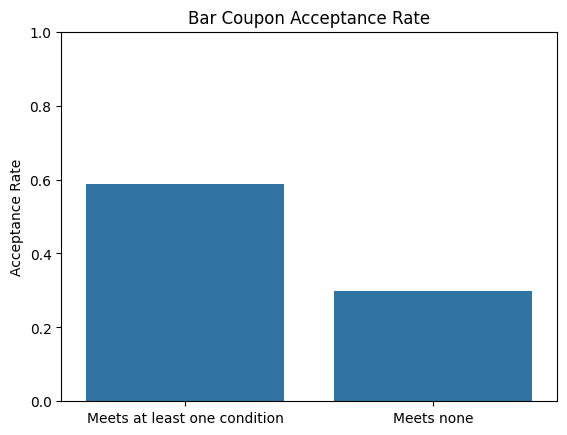

In [28]:
more_than_once = bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])
group1 = bar_coupons[
    (bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])) &
    (bar_coupons['passanger'] != 'Kid(s)') &
    (bar_coupons['maritalStatus'] != 'Widowed')
]

group2 = bar_coupons[
    (bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])) &
    (bar_coupons['age'].isin(['below21', '21', '26']))
]

group3 = bar_coupons[
    (bar_coupons['RestaurantLessThan20'].isin(['4~8', 'gt8'])) &
    (bar_coupons['income'].isin([
        'Less than $12500',
        '$12500 - $24999',
        '$25000 - $37499',
        '$37500 - $49999'
    ]))
]

print(f"Group 1(go to bars more than once a month, had passengers that were not a kid, and were not widowed): {group1['Y'].mean():.1%}")
print(f"Group 2(go to bars more than once a month and are under the age of 30): {group2['Y'].mean():.1%}")
print(f"Group 3go to cheap restaurants more than 4 times a month and income is less than 50K.: {group3['Y'].mean():.1%}")

#GRAPHICAL ANALYSIS

more_than_once = bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])

condition1 = (
    more_than_once &
    (bar_coupons['passanger'] != 'Kid(s)') &
    (bar_coupons['maritalStatus'] != 'Widowed')
)

condition2 = (
    more_than_once &
    bar_coupons['age'].isin(['below21', '21', '26'])
)

condition3 = (
    bar_coupons['RestaurantLessThan20'].isin(['4~8', 'gt8']) &
    bar_coupons['income'].isin([
        'Less than $12500',
        '$12500 - $24999',
        '$25000 - $37499',
        '$37500 - $49999'
    ])
)
# Define OR
meets_condition = condition1 | condition2 | condition3

meets_any = bar_coupons[meets_condition]
meets_none = bar_coupons[~meets_condition]

rate_any = meets_any['Y'].mean()
rate_none = meets_none['Y'].mean()

print(f"Meets at least one condition: {rate_any:.1%}")
print(f"Meets none: {rate_none:.1%}")

comparison = pd.DataFrame({
    'Group': ['Meets at least one condition', 'Meets none'],
    'Acceptance Rate': [rate_any, rate_none]
})

ax = sns.barplot(
    data=comparison,
    x='Group',
    y='Acceptance Rate'
)

plt.title('Bar Coupon Acceptance Rate')
plt.xlabel('')
plt.ylabel('Acceptance Rate')
plt.ylim(0, 1)

plt.show()

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

**Bar Coupon Findings**

**Goal**

Identify the behavioral, demographic, and situational characteristics associated with higher Bar coupon acceptance, with particular emphasis on whether existing bar-going frequency can distinguish likely accepters from non-accepters.


Based on the observations my hypothesis is that drivers wo already have a stronger affinity to go to bars are more likley to accept a bar coupon.

The Bar coupon analysis showed that customer behavior was the strongest observed indicator of acceptance. Overall, only 41.0% of Bar coupons were accepted, but acceptance increased substantially among customers whose existing behavior aligned with the offer.

**Observations**

| Driver segment                                         | Acceptance rate |
| ------------------------------------------------------ | --------------: |
| Overall Bar coupon acceptance                          |       **41.0%** |
| Bar visits ≤3 times/month                              |       **37.1%** |
| Bar visits >3 times/month                              |       **76.9%** |
| Bar >1/month and age >25                               |       **69.5%** |
| Bar >1/month, no kid passenger, non-farming occupation |       **71.3%** |
| Meets at least one broader targeting condition         |       **58.9%** |
| Meets none of those conditions                         |       **29.8%** |

**Inference**

* Frequency matters most: Customers who already visit bars frequently were significantly more likely to accept Bar coupons.
Context strengthens the pattern:
* Acceptance remained high when frequent bar-going was combined with factors such as age and passenger type.

**Recommendation**

Prioritize Bar coupons for customers who already demonstrate regular bar-going behavior rather than distributing the coupons uniformly. Visit frequency should be the primary targeting signal, while contextual factors such as passenger type and age can provide additional segmentation.

In [29]:
## Based on the observations my hyposthesis would be that drivers who already have a stronger affinity to go to bars are mpre likely to accept a bar coupon.
## The following observations support this:
## 1. Overall bar coupon acceptance was about 40%
## 2. Drivers who visited bars more than 3 times per month accepted about 76.9%
## 3. Drivers who went to bars more than once a month and were over 25 accepted about 69.5%.
## 4. Drivers who went to bars more than once a month, had no kid passenger, and were not widowed accepted about 71.3%.
## 5. Drivers meeting at least one of the three broader conditions in the previous analysis accepted about 58.9%, versus 29.8% among those meeting none.

### I hypothesize that prior bar-going behavior is one of the strongest indicators of bar coupon acceptance.
### Overall, the coupon appears most effective when offered to drivers whose existing lifestyle and current context align with the coupon.

Results:tivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

In [30]:
#Coffee House Coupons
coffee_coupons = coupons[coupons['coupon'] == 'Coffee House']
coffee_coupons.head(20)
coffee_coupons.shape

(3996, 25)

In [31]:
# Proportion of Coffee House Coupons accepted
coffee_accept = coffee_coupons['Y'].mean()
coffee_accept

np.float64(0.49924924924924924)

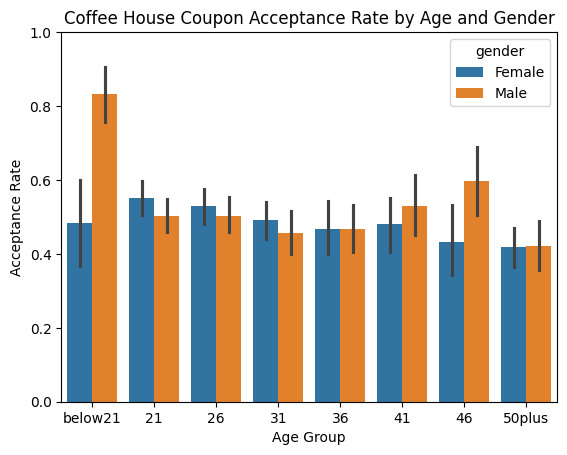

,age,gender,Y
0,21,Female,0.550369
1,21,Male,0.502101
2,26,Female,0.528846
3,26,Male,0.501171
4,31,Female,0.490411
5,31,Male,0.457364
6,36,Female,0.468571
7,36,Male,0.466960
8,41,Female,0.481081
9,41,Male,0.528571


In [32]:
# Compare the acceptance rate by gender and age
age_gender_acceptance = (
    coffee_coupons
    .groupby(['age', 'gender'])['Y']
    .mean()
    .reset_index()
)

age_gender_acceptance

#Graphical ANalysis
age_order = [
    'below21', '21', '26', '31',
    '36', '41', '46', '50plus'
]

sns.barplot(
    data=coffee_coupons,
    x='age',
    y='Y',
    hue='gender',
    order=age_order
)

plt.title('Coffee House Coupon Acceptance Rate by Age and Gender')
plt.xlabel('Age Group')
plt.ylabel('Acceptance Rate')
plt.ylim(0, 1)

plt.show()
age_gender_acceptance

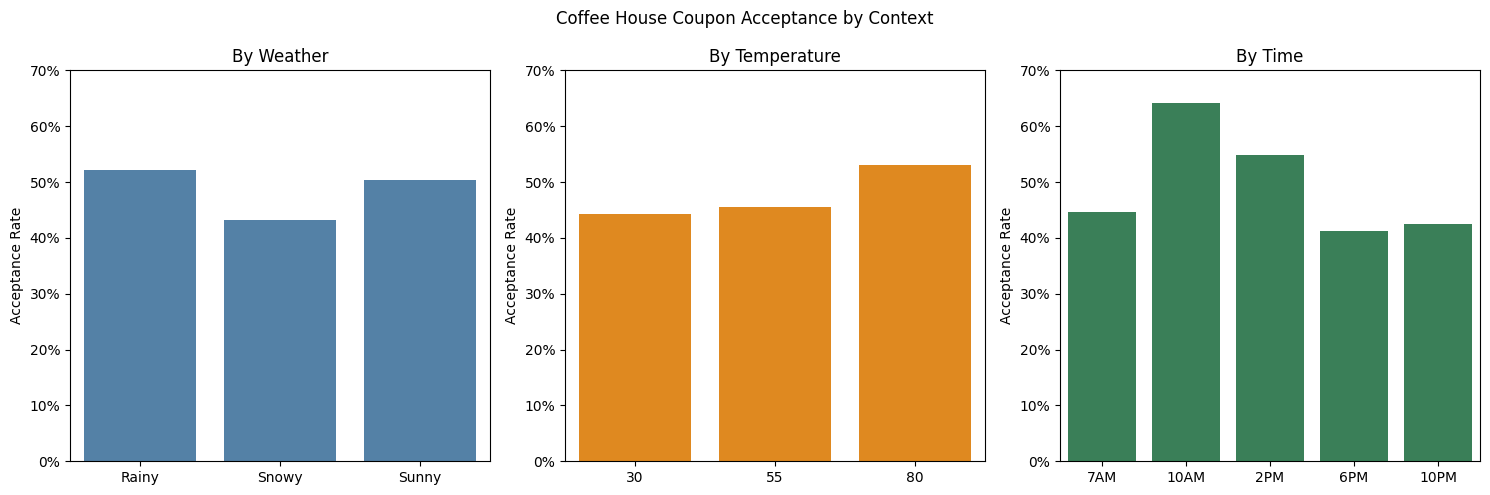

In [33]:
#Compare the acceptance rate by weather, temperature and time of day
# Create the summary tables
weather_summary = (
    coffee_coupons
    .groupby('weather')['Y']
    .agg(observations='count', accepted='sum', acceptance_rate='mean')
    .reset_index()
)

temperature_summary = (
    coffee_coupons
    .groupby('temperature')['Y']
    .agg(observations='count', accepted='sum', acceptance_rate='mean')
    .reset_index()
)

time_summary = (
    coffee_coupons
    .groupby('time')['Y']
    .agg(observations='count', accepted='sum', acceptance_rate='mean')
    .reset_index()
)

#Time Summary
time_order = ['7AM', '10AM', '2PM', '6PM', '10PM']

time_summary['time'] = pd.Categorical(
    time_summary['time'],
    categories=time_order,
    ordered=True
)

time_summary = time_summary.sort_values('time')
time_summary

## GRAPH ANALYSIS
from matplotlib.ticker import PercentFormatter
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.barplot(
    data=weather_summary,
    x='weather',
    y='acceptance_rate',
    ax=axes[0],
    color='steelblue'
)

sns.barplot(
    data=temperature_summary,
    x='temperature',
    y='acceptance_rate',
    ax=axes[1],
    color='darkorange'
)

sns.barplot(
    data=time_summary,
    x='time',
    y='acceptance_rate',
    ax=axes[2],
    color='seagreen'
)

axes[0].set_title('By Weather')
axes[1].set_title('By Temperature')
axes[2].set_title('By Time')

for axis in axes:
    axis.set_xlabel('')
    axis.set_ylabel('Acceptance Rate')
    axis.set_ylim(0, 0.7)
    axis.yaxis.set_major_formatter(PercentFormatter(1))

plt.suptitle('Coffee House Coupon Acceptance by Context')
plt.tight_layout()
plt.show()

In [34]:
# Compare the acceptance rate of coffee house coupons of Drivers who regularly visit coffee houses and receive a coupon during typical
# coffee-consumption times, such as 10AM or 2PM, will have higher acceptance rates than other drivers.

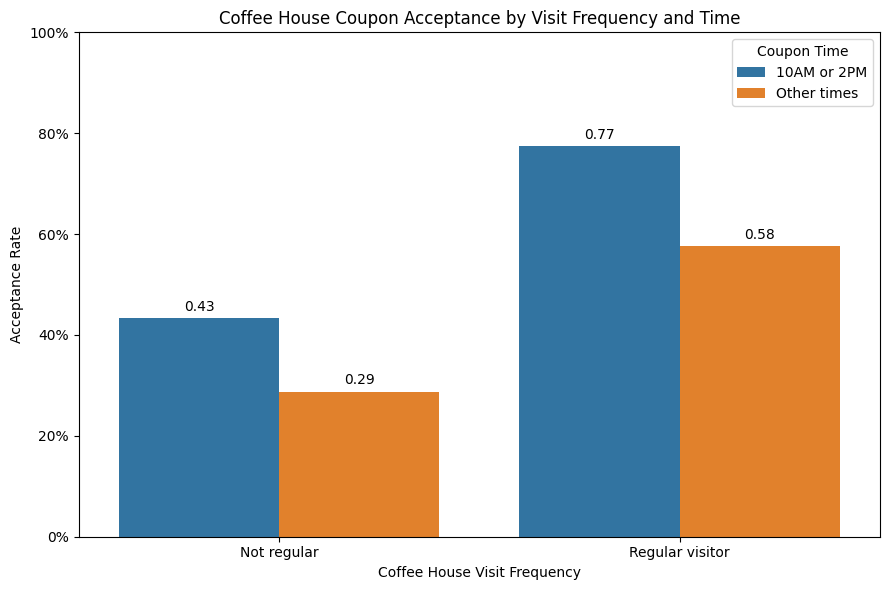

In [35]:
#Regular visitor ['1~3', '4~8', 'gt8']
#Typical coffee times ['10AM', '2PM']

coffee_coupons = coffee_coupons.copy()

coffee_coupons['regular_visitor'] = (
    coffee_coupons['CoffeeHouse']
    .isin(['1~3', '4~8', 'gt8'])
)

coffee_coupons['typical_time'] = (
    coffee_coupons['time']
    .isin(['10AM', '2PM'])
)

coffee_coupons['visitor_group'] = (
    coffee_coupons['regular_visitor']
    .map({
        True: 'Regular visitor',
        False: 'Not regular'
    })
)

coffee_coupons['time_group'] = (
    coffee_coupons['typical_time']
    .map({
        True: '10AM or 2PM',
        False: 'Other times'
    })
)


coffee_summary = (
    coffee_coupons
    .groupby(['visitor_group', 'time_group'])['Y']
    .agg(
        observations='count',
        accepted='sum',
        acceptance_rate='mean'
    )
    .reset_index()
)

coffee_summary

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=coffee_summary,
    x='visitor_group',
    y='acceptance_rate',
    hue='time_group'
)

plt.title(
    'Coffee House Coupon Acceptance by Visit Frequency and Time'
)
plt.xlabel('Coffee House Visit Frequency')
plt.ylabel('Acceptance Rate')
plt.ylim(0, 1)

ax.yaxis.set_major_formatter(PercentFormatter(1))

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f',
        padding=3
    )

plt.legend(title='Coupon Time')
plt.tight_layout()
plt.show()

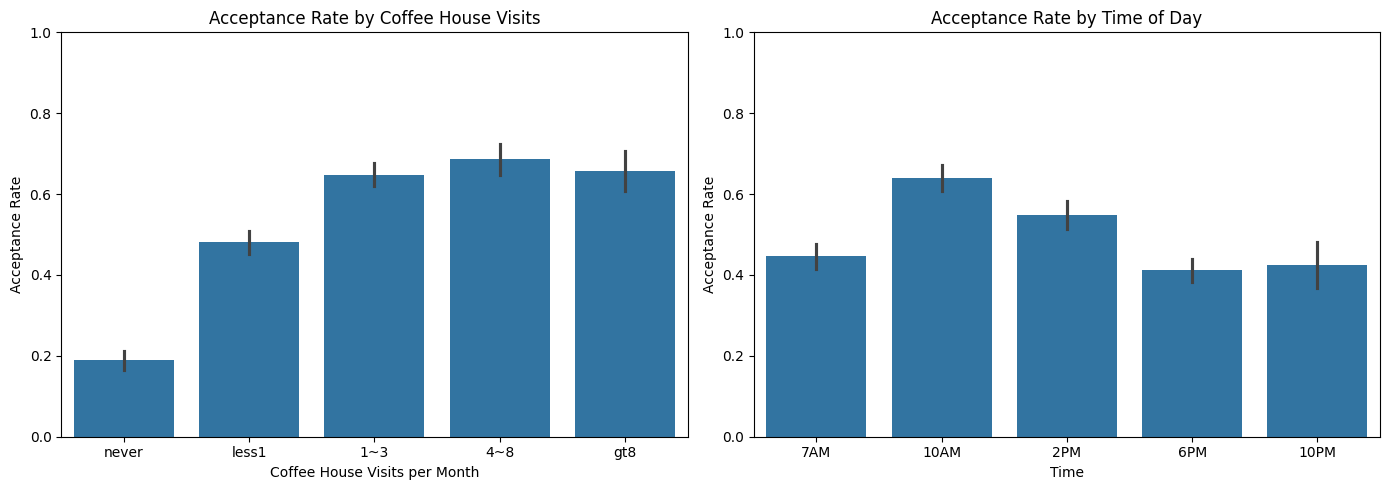

In [36]:
#Acceptance Rate and Coffe House frequency of visit & TIme of Day
plt.figure(figsize=(14, 5))

plt.subplot(121)

sns.barplot(
    data=coffee_coupons,
    x='CoffeeHouse',
    y='Y',
    order=['never', 'less1', '1~3', '4~8', 'gt8']
)

plt.title('Acceptance Rate by Coffee House Visits')
plt.xlabel('Coffee House Visits per Month')
plt.ylabel('Acceptance Rate')
plt.ylim(0, 1)


plt.subplot(122)

sns.barplot(
    data=coffee_coupons,
    x='time',
    y='Y',
    order=['7AM', '10AM', '2PM', '6PM', '10PM']
)

plt.title('Acceptance Rate by Time of Day')
plt.xlabel('Time')
plt.ylabel('Acceptance Rate')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


**Coffee House Coupon Findings**

**Goal**

Identify the customer behaviors and driving contexts associated with higher Coffee House coupon acceptance, particularly whether regular Coffee House visitors are more receptive when coupons are offered at relevant times


Overall, 49.9% of Coffee House coupons were accepted. The Coffee House analysis showed that customer behavior in frequency and timing were the strongest observed indicators of acceptance.


| Driver segment / context                | Acceptance rate |
| --------------------------------------- | --------------: |
| Overall Coffee House acceptance         |       **49.9%** |
| Regular visitor + coupon at 10AM/2PM    |       **77.4%** |
| Regular visitor + other times           |       **57.7%** |
| Nonregular visitor + coupon at 10AM/2PM |       **43.4%** |
| Nonregular visitor + other times        |       **28.8%** |
| 10AM overall                            |       **64.1%** |
| 2PM overall                             |       **54.8%** |
| 80°F                                    |       **53.0%** |


**Interpretation**
* **Prior behavior matters**: Regular Coffee House visitors were substantially more likely to accept coupons than infrequent visitors.
* **Timing matters**: Acceptance was highest at 10AM, followed by 2PM, suggesting that coupons perform better around typical coffee-consumption periods.
* **Behavior + timing produced the strongest result:** Regular visitors receiving coupons at 10AM or 2PM reached a 77.4% acceptance rate.
* **Weather and temperature had smaller effects**: Acceptance was higher at 80°F and lower during snowy conditions, but these patterns were less pronounced than visit frequency and time.
* **Age and Gender** showed some variation, with the 21 and below segment Male having higher acceptance rates compared to others.

**Hyposthesis**

Coffee House coupon acceptance is more strongly associated with the combination of existing Coffee House visit behavior and relevant timing than with demographic characteristics alone.

The strongest observed segment, regular Coffee House visitors receiving a coupon at 10AM or 2PM, achieved 77.4% acceptance, compared with only 28.8% among nonregular visitors receiving coupons at other times.